# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- Дмитрів Мар'ян (1/3)
- Святослав Мандзюк (1/3)
- Юрій Заліщук (1/3)


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np

team_id: int = 21

random.seed(team_id)
np.random.seed(team_id)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


### Setup

We work over $\mathbb{F}_2$: all matrix products are reduced mod 2. The syndrome $z = rH$ read as a binary number $z_1 + 2z_2 + 4z_3$ gives the position of the corrupted bit (0 means no error detected). We check that $GH = 0 \pmod 2$, i.e. every codeword has zero syndrome.

In [2]:
import matplotlib.pyplot as plt
from scipy import stats

G = np.array([
    [1, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1],
])

H = np.array([
    [1, 0, 1, 0, 1, 0, 1],
    [0, 1, 1, 0, 0, 1, 1],
    [0, 0, 0, 1, 1, 1, 1],
]).T

print("GH mod 2 =\n", (G @ H) % 2)

p = (2 + team_id / 4) / 100
print("p =", p)

FIX = np.vstack([np.zeros(7, dtype=int), np.eye(7, dtype=int)])

def simulate(N, p):
    m = np.random.randint(0, 2, size=(N, 4))

    c = (m @ G) % 2

    errors = (np.random.random((N, 7)) < p).astype(int)
    r = (c + errors) % 2

    z = (r @ H) % 2
    bad_bit = z[:, 0] + 2 * z[:, 1] + 4 * z[:, 2]

    r_star = (r + FIX[bad_bit]) % 2

    m_star = r_star[:, [2, 4, 5, 6]]
    return m, m_star

GH mod 2 =
 [[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
p = 0.0725


### 1.1 Estimate of $p^*$

Let $I_j = \mathbb{1}\{m^*_j = m_j\}$ be the indicator that the $j$-th message was transmitted correctly. The $I_j$ are i.i.d. Bernoulli($p^*$), so $E(I_j) = p^*$ and
$$\hat p = \frac{1}{N}\sum_{j=1}^N I_j .$$

In [3]:
N = 100_000
m, m_star = simulate(N, p)

success = np.all(m == m_star, axis=1).astype(int)

p_hat = success.mean()

p_star = (1 - p) ** 7 + 7 * p * (1 - p) ** 6

print("p_hat =", p_hat)
print("p* =", p_star)

p_hat = 0.91405
p* = 0.9135564974947045


**Why $\hat p \approx p^*$ for large $N$.** By the (strong) Law of Large Numbers, the sample mean of i.i.d. r.v.'s with finite expectation converges to that expectation: $\hat p = \bar I_N \xrightarrow{a.s.} E(I_1) = p^*$.

**Theoretical check.** The minimal distance of the $[7,4]$ Hamming code is 3, so the decoder corrects any single error. If $\ge 2$ bits are corrupted, the decoder either sees a zero syndrome (the received word is another codeword) or "corrects" a wrong bit. In both cases it outputs a codeword different from $c$, hence $m^* \ne m$. Therefore
$$p^* = P(\text{at most one of 7 bits corrupted}) = (1-p)^7 + 7p(1-p)^6,$$
and the simulation agrees with this value very well.

### 1.2 Confidence interval

By the CLT, $\dfrac{\hat p - p^*}{\sigma/\sqrt N} \approx \mathcal N(0,1)$, where $\sigma^2 = \operatorname{Var}(I_1) = p^*(1-p^*)$. Replacing $\sigma$ by the sample standard deviation $s$,
$$P\left(|\hat p - p^*| < \varepsilon\right) \approx 0.95 \quad\text{for}\quad \varepsilon = z_{0.975}\,\frac{s}{\sqrt N}, \qquad z_{0.975} \approx 1.96 .$$
To guarantee $\varepsilon \le 0.03$ we need $N \ge \left(\dfrac{z_{0.975}\, s}{0.03}\right)^2$. Since for any indicator $\sigma^2 = q(1-q) \le \frac14$, the choice $N \ge \left(\dfrac{1.96 \cdot 0.5}{0.03}\right)^2 \approx 1068$ works regardless of the unknown $p^*$.

In [4]:
z = stats.norm.ppf(0.975)

s = success.std(ddof=1)

eps = z * s / np.sqrt(N)
print("z =", z)
print("s =", s)
print("eps =", eps)
print("95% CI:", p_hat - eps, "...", p_hat + eps)

print("N for eps <= 0.03 (with our s):", int(np.ceil((z * s / 0.03) ** 2)))

print("N for eps <= 0.03 (worst case, s = 0.5):", int(np.ceil((z * 0.5 / 0.03) ** 2)))

z = 1.959963984540054
s = 0.2802916037519343
eps = 0.0017372334360212748
95% CI: 0.9123127665639787 ... 0.9157872334360213
N for eps <= 0.03 (with our s): 336
N for eps <= 0.03 (worst case, s = 0.5): 1068


**Comment.** Using the sample $s \approx \sqrt{\hat p(1-\hat p)}$ we get $N = 336$, which relies on our estimate of $p^*$. The worst-case bound $\sigma \le \frac12$ gives $N \ge 1068$, which guarantees $\varepsilon \le 0.03$ for any value of $p^*$, so this is the safe choice. Our actual $N = 10^5$ gives $\varepsilon \approx 0.002$, and the interval indeed contains the theoretical $p^*$.

### 1.3 Distribution of the number of wrong bits in $m^*$

k   simulation   exact      Bin(4, q)
0    0.91405      0.91356     0.85599
1    0.03436      0.03474     0.13572
2    0.03662      0.03705     0.00807
3    0.01497      0.01466     0.00021
4    0.0      0.0     0.0


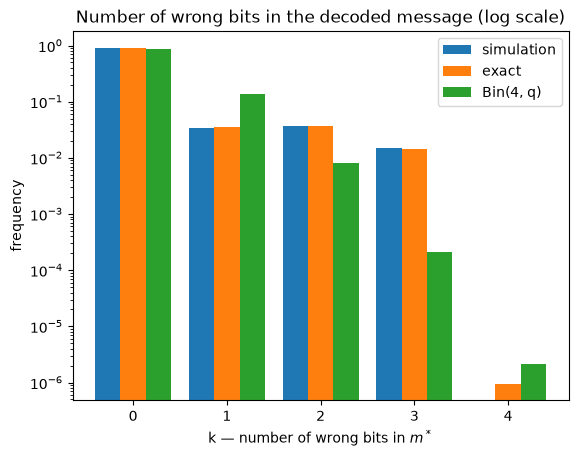

In [5]:
k = np.sum(m != m_star, axis=1)

freq = np.bincount(k, minlength=5) / N

q = k.mean() / 4
binom = stats.binom.pmf([0, 1, 2, 3, 4], 4, q)

E = np.array([[(e >> j) & 1 for j in range(7)] for e in range(128)])
prob_E = p ** E.sum(axis=1) * (1 - p) ** (7 - E.sum(axis=1))
z_E = (E @ H) % 2
E_star = (E + FIX[z_E[:, 0] + 2 * z_E[:, 1] + 4 * z_E[:, 2]]) % 2
k_E = E_star[:, [2, 4, 5, 6]].sum(axis=1)
exact = np.bincount(k_E, weights=prob_E, minlength=5)

print("k   simulation   exact      Bin(4, q)")
for i in range(5):
    print(i, "  ", round(freq[i], 5), "    ", round(exact[i], 5), "   ", round(binom[i], 5))

ks = np.arange(5)
plt.bar(ks - 0.27, freq, width=0.27, label="simulation")
plt.bar(ks, exact, width=0.27, label="exact")
plt.bar(ks + 0.27, binom, width=0.27, label="Bin(4, q)")
plt.yscale("log")
plt.xticks(ks)
plt.xlabel("k — number of wrong bits in $m^*$")
plt.ylabel("frequency")
plt.title("Number of wrong bits in the decoded message (log scale)")
plt.legend()
plt.show()

**Is it a known distribution?** If the 4 bits of $m^*$ were wrong independently with the same probability $q$, the number of wrong bits $k$ would be $\text{Bin}(4, q)$. The comparison shows that this is **not** the case: the simulated distribution has far more mass at $k = 2, 3$ than $\text{Bin}(4,q)$ predicts.

**Exact distribution of $k$.** The code is linear, so $m^* - m$ depends only on the error vector $e \in \mathbb F_2^7$ and not on the message itself. Hence we can take $m = 0$ and enumerate all $2^7 = 128$ error vectors, each with probability $p^{|e|}(1-p)^{7-|e|}$, where $|e|$ is the number of corrupted bits:
$$P(k = j) = \sum_{e \,:\, k(e) = j} p^{|e|}(1-p)^{7-|e|}.$$
The simulated frequencies agree with these exact values, which confirms both the simulation and the decoder.

The reason is that errors in the decoded bits are strongly dependent: the decoder fails only when $\ge 2$ channel errors occur, and then it outputs a *different codeword*, which differs from $c$ in at least 3 positions (minimal distance 3). So errors come in "bursts", and once one bit of $m^*$ is wrong, others are likely wrong too. Hence $k$ does not follow a binomial (or any other standard) distribution. Its law is determined by the code structure. Note also that $k=4$ is practically impossible: it requires the decoded codeword to differ from $c$ by the all-ones word $1111111$, i.e. at least 6 channel errors.

### Conclusion for Task 1

The simulation estimate $\hat p \approx 0.914$ agrees with the theoretical value $p^* = (1-p)^7 + 7p(1-p)^6 \approx 0.914$ up to the third decimal place, as expected from the LLN for $N = 10^5$. The CLT-based 95% confidence interval has half-length $\varepsilon \approx 0.002$ and contains $p^*$, so the estimate is reliable. Also, $N \ge 1068$ is enough for $\varepsilon \le 0.03$ for any $p^*$.

The result also agrees with common sense: the Hamming code fixes the most likely failure (a single corrupted bit), so the message arrives correctly in about 91% of cases. Without coding, all 4 bits would have to survive, which happens with probability $(1-p)^4 \approx 0.74$. When the decoder does fail, it usually corrupts 2–3 bits at once, so the number of wrong bits in $m^*$ is not binomial: errors in the decoded bits are dependent.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


### 2.1 Parameter of the Poisson distribution

Atomic mass of $^{137}\text{Cs}$: $M \approx 136.907$ g/mol. For team 21, $m = 31 \times 10^{-14}$ g. Then

$$
N = \frac{m}{M} N_A, \qquad \lambda = \frac{\ln 2}{T}, \qquad \mu = N\lambda,
$$

with $T = 30.1 \cdot 365.25 \cdot 24 \cdot 3600$ seconds.

In [6]:
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ecdf

K = 10_000                      # number of repetitions for e.c.d.f.'s
Z95 = stats.norm.ppf(0.975)     # two-sided 95% quantile, ~1.96
Z05 = stats.norm.ppf(0.95)      # one-sided 95% quantile, ~1.645

N_A = 6e23
M_Cs = 136.907                                   # g/mol
T_half = 30.1 * 365.25 * 24 * 3600               # seconds
mass = (10 + team_id) * 1e-14                    # grams

n_atoms = mass / M_Cs * N_A
lam_decay = np.log(2) / T_half
mu = n_atoms * lam_decay
print(f"number of atoms N = {n_atoms:.4e}")
print(f"decay constant = {lam_decay:.4e} 1/s")
print(f"Poisson parameter mu = N*lambda = {mu:.5f}")

number of atoms N = 1.3586e+09
decay constant = 7.2972e-10 1/s
Poisson parameter mu = N*lambda = 0.99138


So $X_i \sim \text{Poisson}(\mu)$ with $\mu \approx 0.991$: about one decay per second per sample.

### 2.2 CLT for the sample means

$E X_i = \operatorname{Var} X_i = \mu$. By the CLT,

$$
\bar X_n \approx \mathcal N\!\left(\mu, \frac{\mu}{n}\right).
$$

For each $n \in \{5, 10, 50\}$ we simulate $K = 10\,000$ sample means and compare their e.c.d.f. with the c.d.f. of
$\mathcal N(\mu, \mu/n)$ on a grid of 200 points within $\mu \pm 3\sigma$.

n = 5: mean of s = 0.9946 (mu = 0.9914), var of s = 0.19831 (mu/n = 0.19828), max diff = 0.1000
n = 10: mean of s = 0.9898 (mu = 0.9914), var of s = 0.09711 (mu/n = 0.09914), max diff = 0.0811
n = 50: mean of s = 0.9898 (mu = 0.9914), var of s = 0.01972 (mu/n = 0.01983), max diff = 0.0399


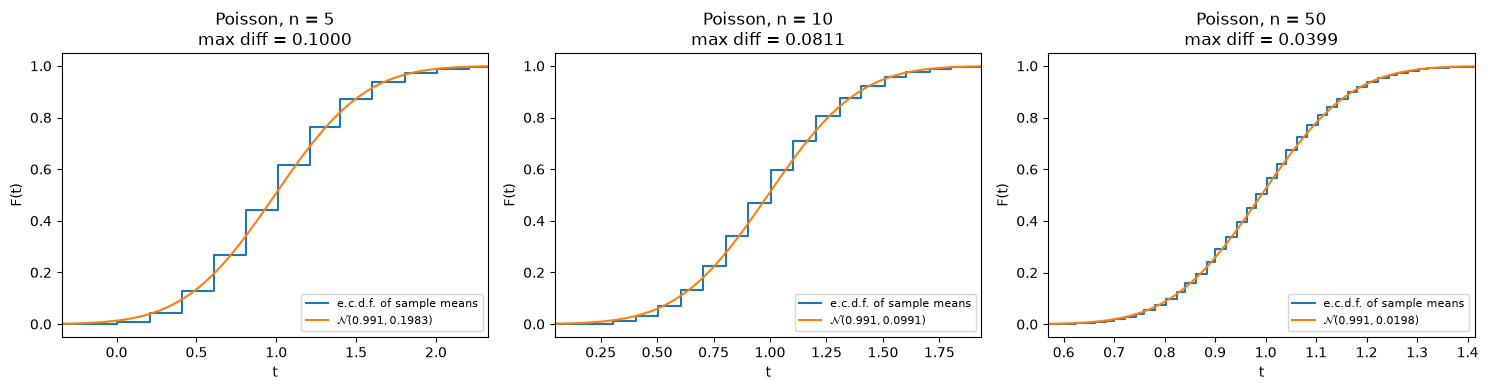

In [7]:
def compare_with_normal(s, mu, sigma, ax, title):
    """Plot e.c.d.f. of s against N(mu, sigma^2) and return max |F_s - F_Z| on the grid."""
    Fs = ecdf(s).cdf.evaluate
    Fz = stats.norm(mu, sigma).cdf
    t = np.linspace(mu - 3 * sigma, mu + 3 * sigma, 200)
    diff = np.max(np.abs(Fs(t) - Fz(t)))
    ax.step(t, Fs(t), where="post", label="e.c.d.f. of sample means")
    ax.plot(t, Fz(t), label=rf"$\mathcal{{N}}({mu:.3f}, {sigma**2:.4f})$")
    ax.set(title=f"{title}\nmax diff = {diff:.4f}", xlabel="t", ylabel="F(t)", xlim=(t[0], t[-1]))
    ax.legend(loc="lower right", fontsize=8)
    return diff


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s_means = np.random.poisson(mu, size=(K, n)).mean(axis=1)
    sigma = np.sqrt(mu / n)
    d = compare_with_normal(s_means, mu, sigma, ax, f"Poisson, n = {n}")
    print(f"n = {n}: mean of s = {s_means.mean():.4f} (mu = {mu:.4f}), "
          f"var of s = {s_means.var(ddof=1):.5f} (mu/n = {mu / n:.5f}), max diff = {d:.4f}")
plt.tight_layout()
plt.show()

### 2.3 Largest $n$ with $P(S_n < 100) > 0.95$

$S_n = X_1 + \dots + X_n \sim \text{Poisson}(n\mu)$ (a sum of independent Poissons is Poisson). We want the largest
$n$ with $P(S_n < a) > 0.95$, i.e. $P(S_n \ge a) < 0.05$, where $a = 100$.

**Markov.** $P(S_n \ge a) \le \dfrac{E S_n}{a} = \dfrac{n\mu}{a}$, so $n\mu/a \le 0.05$ is enough:
$n \le \dfrac{0.05\,a}{\mu}$.

**Chernoff.** For $t > 0$, $P(S_n \ge a) \le e^{-ta} E e^{tS_n} = \exp\!\big(n\mu(e^t - 1) - ta\big)$.
The minimum is at $e^t = a/(n\mu)$ (valid when $n\mu < a$), which gives

$$
P(S_n \ge a) \le e^{-n\mu}\left(\frac{e\,n\mu}{a}\right)^{a}.
$$

We find the largest $n$ for which this is $\le 0.05$.

**CLT.** $S_n \approx \mathcal N(n\mu, n\mu)$, so
$P(S_n < a) \approx \Phi\!\left(\dfrac{a - n\mu}{\sqrt{n\mu}}\right) > 0.95 \iff \dfrac{a - n\mu}{\sqrt{n\mu}} > z_{0.95} \approx 1.645$.

Markov and Chernoff give **guaranteed** sufficient conditions. The CLT gives only an approximation, with no guarantee
attached. For each $n$ we also estimate $P(S_n < a)$ by simulation ($K$ sums of $n$ Poisson values) and compute the
exact Poisson c.d.f. as a reference.

Markov bound: n <= 5
Chernoff bound: n <= 78
CLT approximation: n <= 85
Simulation (K=10000): n <= 84
Exact Poisson: n <= 84

  n   simulated   exact     CLT
 81   0.9817    0.9813   0.9860
 82   0.9741    0.9755   0.9810
 83   0.9666    0.9682   0.9746
 84   0.9599    0.9593   0.9666
 85   0.9487    0.9485   0.9567
 86   0.9325    0.9357   0.9448
 87   0.9166    0.9207   0.9306


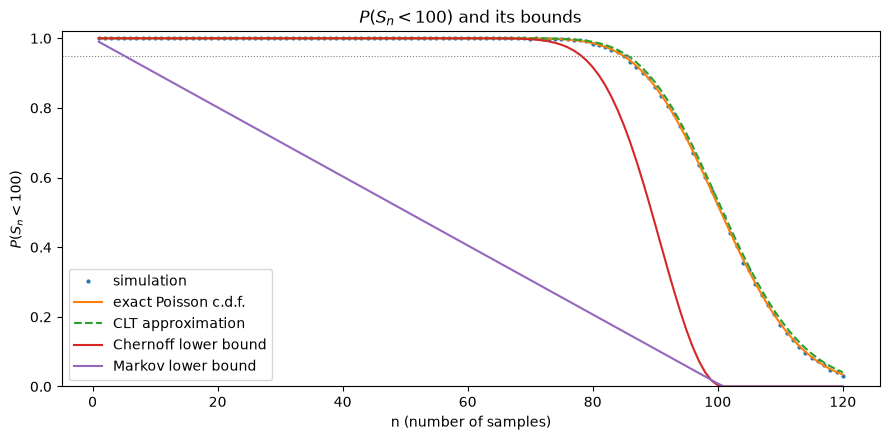

In [8]:
a = 100
ns = np.arange(1, 121)
emp_prob = np.array([(np.random.poisson(mu, size=(K, n)).sum(axis=1) < a).mean() for n in ns])
exact_prob = stats.poisson.cdf(a - 1, ns * mu)

markov_tail = ns * mu / a
chernoff_tail = np.where(ns * mu < a, np.exp(-ns * mu) * (np.e * ns * mu / a)**a, 1.0)
clt_prob = stats.norm.cdf((a - ns * mu) / np.sqrt(ns * mu))


def largest(mask):
    return ns[mask].max() if mask.any() else 0


n_markov = largest(markov_tail <= 0.05)
n_chernoff = largest(chernoff_tail <= 0.05)
n_clt = largest(clt_prob > 0.95)
n_emp = largest(emp_prob > 0.95)
n_exact = largest(exact_prob > 0.95)

print(f"Markov bound: n <= {n_markov}")
print(f"Chernoff bound: n <= {n_chernoff}")
print(f"CLT approximation: n <= {n_clt}")
print(f"Simulation (K={K}): n <= {n_emp}")
print(f"Exact Poisson: n <= {n_exact}")
print()
print("  n   simulated   exact     CLT")
for n in range(n_exact - 3, n_exact + 4):
    i = n - 1
    print(f"{n:3d}   {emp_prob[i]:.4f}    {exact_prob[i]:.4f}   {clt_prob[i]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ns, emp_prob, ".", ms=4, label="simulation")
ax.plot(ns, exact_prob, label="exact Poisson c.d.f.")
ax.plot(ns, clt_prob, "--", label="CLT approximation")
ax.plot(ns, np.clip(1 - chernoff_tail, 0, 1), label="Chernoff lower bound")
ax.plot(ns, np.clip(1 - markov_tail, 0, 1), label="Markov lower bound")
ax.axhline(0.95, color="grey", lw=0.8, ls=":")
ax.set(xlabel="n (number of samples)", ylabel=r"$P(S_n < 100)$", title=r"$P(S_n < 100)$ and its bounds", ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
plt.show()

### Conclusions (Task 2)

* **2.1** A $31\cdot10^{-14}$ g sample of $^{137}$Cs has $N \approx 1.36\cdot10^{9}$ atoms and $\lambda \approx 7.30\cdot10^{-10}$ s$^{-1}$, so $X_i \sim \text{Poisson}(\mu)$ with $\mu \approx 0.991$. The Poisson model fits well here: there are many atoms, each with a tiny decay probability, and since $T$ is about 30 years, $N$ is effectively constant.
* **2.2** The sample means follow $\mathcal N(\mu, \mu/n)$. The simulated mean and variance of $\mathbf s$ agree with $\mu$ and $\mu/n$ to within about 2%. The maximal c.d.f. difference shrinks as $n$ grows: $0.100$ ($n=5$), $0.081$ ($n=10$), $0.040$ ($n=50$). That is roughly in line with the $1/\sqrt n$ rate, as the Berry–Esseen theorem predicts. Most of the gap comes from **discreteness**: $\bar X_n$ takes only values on the lattice $\{j/n\}$, so its e.c.d.f. is a staircase with steps of height $\sim 1/\sqrt n$. The Poisson distribution is also skewed for $\mu \approx 1$ (skewness $1/\sqrt{\mu} \approx 1$). For $n = 50$ the normal approximation is already good.
* **2.3** Largest $n$ with $P(S_n < 100) > 0.95$:

  | method | largest $n$ |
  |---|---|
  | Markov | 5 |
  | Chernoff | 78 |
  | CLT | 85 |
  | simulation ($K=10^4$) | 84 |
  | exact Poisson c.d.f. | 84 |

  Markov is guaranteed but very conservative: it uses only $E S_n$. Chernoff is also guaranteed and is much tighter because it uses the whole m.g.f. Its answer of 78 is only 6 below the truth, and it is the right choice when a **safety guarantee** is needed. The CLT is the most accurate approximation but offers no guarantee, and here it overshoots by one: at $n = 85$ the true probability is $0.9485 < 0.95$. The reason is that the Poisson distribution is right-skewed, so its right tail is heavier than the normal one. A continuity correction ($a - 0.5$) does not fix this here: it still gives $n = 85$. The simulation agrees with the exact answer.

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

### 3.1 CLT for sample means of exponential times

For team 21, $\nu_1 = 21/10 + 1 = 3.1$ min$^{-1}$. For $X_k \sim \mathcal E(\nu_1)$, $E X_k = 1/\nu_1$ and
$\operatorname{Var} X_k = 1/\nu_1^2$. By the CLT,

$$
\bar X_n \approx \mathcal N\!\left(\frac{1}{\nu_1}, \frac{1}{n\nu_1^2}\right).
$$

nu_1 = 3.1
n = 5: mean of s = 0.3244 (1/nu1 = 0.3226), var of s = 0.02053 (1/(n nu1^2) = 0.02081), skewness = 0.818 (theory 2/sqrt(n) = 0.894), max diff = 0.0501
n = 10: mean of s = 0.3223 (1/nu1 = 0.3226), var of s = 0.01033 (1/(n nu1^2) = 0.01041), skewness = 0.655 (theory 2/sqrt(n) = 0.632), max diff = 0.0471
n = 50: mean of s = 0.3220 (1/nu1 = 0.3226), var of s = 0.00210 (1/(n nu1^2) = 0.00208), skewness = 0.256 (theory 2/sqrt(n) = 0.283), max diff = 0.0254


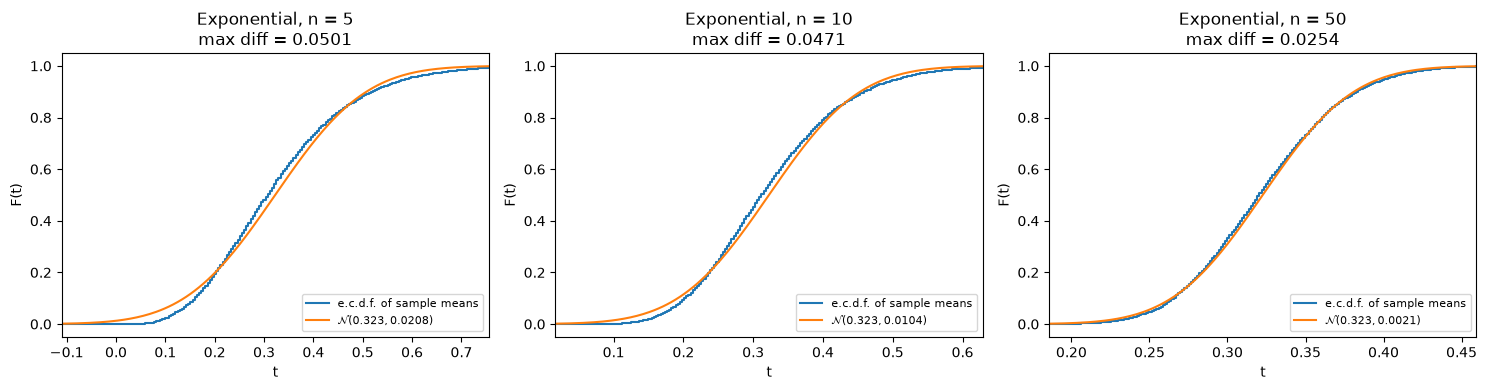

In [9]:
nu1 = team_id / 10 + 1
print(f"nu_1 = {nu1}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s_means = np.random.exponential(scale=1 / nu1, size=(K, n)).mean(axis=1)
    m_n, sigma = 1 / nu1, 1 / (nu1 * np.sqrt(n))
    d = compare_with_normal(s_means, m_n, sigma, ax, f"Exponential, n = {n}")
    print(f"n = {n}: mean of s = {s_means.mean():.4f} (1/nu1 = {m_n:.4f}), "
          f"var of s = {s_means.var(ddof=1):.5f} (1/(n nu1^2) = {sigma**2:.5f}), "
          f"skewness = {stats.skew(s_means):.3f} (theory 2/sqrt(n) = {2 / np.sqrt(n):.3f}), max diff = {d:.4f}")
plt.tight_layout()
plt.show()

### 3.2 Maximal number of samples

**(a) The event in terms of $S$.** With $N$ samples the inter-click times are $\mathcal E(\nu)$, $\nu = N\nu_1$.
"Fewer than 100 clicks in the first minute" is the same event as "the 100th click comes after the first minute":

$$
\{\#\text{clicks in } [0,1] < 100\} = \{S > 1\}, \qquad S = X_1 + \dots + X_{100} \sim \Gamma(100, \nu).
$$

So we need $P(S > 1) \ge 0.95 \iff P(S \le 1) \le 0.05$.

**(b) Bounds.**

*Markov.* We need an upper bound on the **lower** tail of $S$. Applying Markov directly to $S$ only bounds
$P(S \ge 1) \le 100/\nu$, which gives a *necessary* condition $\nu \le 100/0.95$, not a sufficient one. So we apply
Markov to the non-negative variable $1/S$ instead:

$$
P(S \le 1) = P\!\left(\tfrac{1}{S} \ge 1\right) \le E\!\left[\tfrac{1}{S}\right]
= \int_0^\infty \frac{1}{s}\,\frac{\nu^{100} s^{99} e^{-\nu s}}{99!}\,ds = \frac{\nu}{99}.
$$

So $\nu/99 \le 0.05$, i.e. $N \le \dfrac{4.95}{\nu_1}$.

*Chernoff.* For $t > 0$, $P(S \le 1) = P(e^{-tS} \ge e^{-t}) \le e^{t}\,E e^{-tS} = e^{t}\left(\frac{\nu}{\nu + t}\right)^{100}$.
The minimum is at $t = 100 - \nu$ (for $\nu < 100$), which gives

$$
P(S \le 1) \le e^{100 - \nu}\left(\frac{\nu}{100}\right)^{100}.
$$

*CLT.* $S \approx \mathcal N\!\left(\frac{100}{\nu}, \frac{100}{\nu^2}\right)$, so
$P(S \le 1) \approx \Phi\!\left(\dfrac{1 - 100/\nu}{10/\nu}\right) = \Phi\!\left(\dfrac{\nu - 100}{10}\right) \le 0.05
\iff \nu \le 100 - 10\,z_{0.95} \approx 83.55$.

In [10]:
Ns = np.arange(1, 41)
nus = Ns * nu1

markov_S = 100 / nus                                     # Markov on S: upper bound on P(S >= 1)
markov_b = nus / 99
chernoff_b = np.where(nus < 100, np.exp(100 - nus) * (nus / 100)**100, 1.0)
clt_b = stats.norm.cdf((nus - 100) / 10)
exact_b = stats.gamma.cdf(1, a=100, scale=1 / nus)       # P(S <= 1)


def largest_N(mask):
    return Ns[mask].max() if mask.any() else 0


N_markov_S = largest_N(markov_S >= 0.95)
N_markov = largest_N(markov_b <= 0.05)
N_chernoff = largest_N(chernoff_b <= 0.05)
N_clt = largest_N(clt_b <= 0.05)
N_exact = largest_N(exact_b <= 0.05)

print(f"Markov (on S): N <= {N_markov_S}   (necessary condition only, nu <= {100 / 0.95:.2f})")
print(f"Markov (on 1/S): N <= {N_markov}   (nu <= {0.05 * 99:.2f})")
print(f"Chernoff: N <= {N_chernoff}")
print(f"CLT: N <= {N_clt}   (nu <= {100 - 10 * Z05:.2f})")
print(f"Exact (Gamma cdf): N <= {N_exact}")

Markov (on S): N <= 33   (necessary condition only, nu <= 105.26)
Markov (on 1/S): N <= 1   (nu <= 4.95)
Chernoff: N <= 24
CLT: N <= 26   (nu <= 83.55)
Exact (Gamma cdf): N <= 27


**(c)–(e) Simulation.** We take the CLT prediction $N$ and its neighbours, simulate $K$ realizations of
$S = X_1 + \dots + X_{100}$ and estimate $P(S > 1)$.

 N    nu      P(safe) simulated   exact P(S>1)
 1     3.1   1.0000 +- 0.0000       1.0000


24    74.4   0.9971 +- 0.0011       0.9973
25    77.5   0.9937 +- 0.0016       0.9920
26    80.6   0.9785 +- 0.0028       0.9797
27    83.7   0.9552 +- 0.0041       0.9549
28    86.8   0.9129 +- 0.0055       0.9114


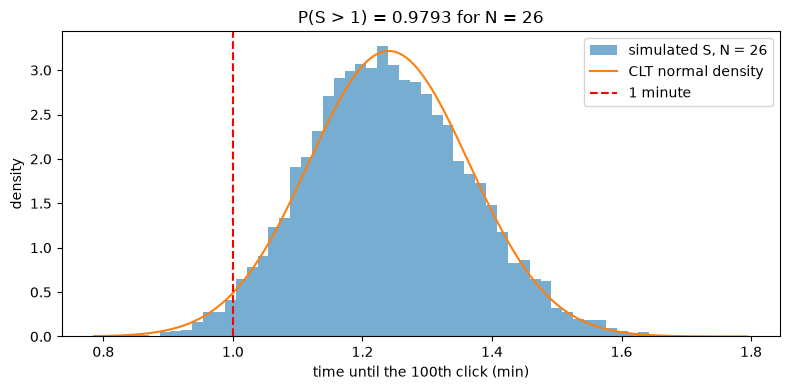

In [11]:
print(" N    nu      P(safe) simulated   exact P(S>1)")
for N_s in sorted({N_markov, N_chernoff, N_clt - 1, N_clt, N_clt + 1, N_clt + 2}):
    nu = N_s * nu1
    S = np.random.exponential(scale=1 / nu, size=(K, 100)).sum(axis=1)
    p_safe = (S > 1).mean()
    half = Z95 * np.sqrt(p_safe * (1 - p_safe) / K)
    print(f"{N_s:2d}  {nu:6.1f}   {p_safe:.4f} +- {half:.4f}       {1 - stats.gamma.cdf(1, a=100, scale=1 / nu):.4f}")

nu = N_clt * nu1
S = np.random.exponential(scale=1 / nu, size=(K, 100)).sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(S, bins=60, density=True, alpha=0.6, label=f"simulated S, N = {N_clt}")
tt = np.linspace(S.min(), S.max(), 300)
ax.plot(tt, stats.norm(100 / nu, 10 / nu).pdf(tt), label="CLT normal density")
ax.axvline(1, color="red", ls="--", label="1 minute")
ax.set(xlabel="time until the 100th click (min)", ylabel="density",
       title=f"P(S > 1) = {(S > 1).mean():.4f} for N = {N_clt}")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusions (Task 3)

* **3.1** $\bar X_n \approx \mathcal N\left(\frac{1}{\nu_1}, \frac{1}{n\nu_1^2}\right) = \mathcal N\left(0.3226, \frac{0.1041}{n}\right)$. The maximal c.d.f. difference is $0.050$ ($n=5$), $0.047$ ($n=10$) and $0.025$ ($n=50$). These are smaller than for the Poisson case because the exponential is continuous, so there are no lattice jumps. The remaining error comes from **skewness**: $\bar X_n$ is exactly $\Gamma(n, n\nu_1)$ with skewness $2/\sqrt n$, and the simulated skewness (0.82, 0.66, 0.26) matches this. The e.c.d.f. lies slightly above the normal c.d.f. in the middle (the median of the gamma distribution is below its mean) and slightly below it on the far left (its left tail is lighter than the normal one). Both are signs of the right-skewed gamma distribution. The approximation improves at rate $1/\sqrt n$.
* **3.2** The location is safe when $S = X_1 + \dots + X_{100} > 1$. Maximal number of samples:

  | method | max $N$ ($\nu = 3.1N$) |
  |---|---|
  | Markov (applied to $1/S$) | 1 |
  | Chernoff | 24 |
  | CLT | 26 |
  | exact ($\Gamma$ c.d.f.) | 27 |

  The simulation with the CLT prediction $N = 26$ ($\nu = 80.6$) gives $P(\text{safe}) \approx 0.979 \ge 0.95$, so the requirement is met. $N = 27$ still passes ($0.955$, exact $0.955$), and $N = 28$ fails ($0.913$). Here the CLT is slightly **conservative**: $S$ is right-skewed, so its lower tail is lighter than the normal one. In Task 2 the CLT was slightly **optimistic**. The direction of the error depends on which tail matters. Markov and Chernoff hold for certain but are pessimistic. Markov applied directly to $S$ bounds $P(\text{safe})$ only from above, so it gives just a necessary condition: with $N \ge 34$ the place is certainly not safe with probability $0.95$. Markov on $1/S$ gives a sufficient condition but allows only a single sample. **Answer: $N = 27$.** This is the exact value from the $\Gamma$ c.d.f., and the simulation confirms it: $P(\text{safe}) \approx 0.955 \ge 0.95$ for $N = 27$, while $N = 28$ already fails. If only a bound that holds for certain is acceptable, the Chernoff value $N = 24$ is the safe choice.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### Part 1

**(a) Why $E(1/X) \ne 1/E(X)$.** Expectation is linear, but $g(x) = 1/x$ is not linear, and in general
$E\,g(X) \ne g(E X)$. On $(0, \infty)$ the function $1/x$ is strictly convex, so **Jensen's inequality** gives
$E(1/X) \ge 1/E(X)$ for positive $X$, with equality only when $X$ is constant. A simple example: $X \in \{1, 3\}$ with
probability $1/2$ each. Then $E X = 2$ and $1/E X = 0.5$, while $E(1/X) = \frac12(1 + \frac13) = \frac23$.
Worse, $E(1/X)$ may not exist at all, even when $E X$ is finite. This happens whenever $X$ has positive density at $0$,
because then $\int f(x)/|x|\,dx$ diverges near $0$.

In [12]:
from math import ceil

mu_x, sigma_x = 5, np.sqrt(10)
x = np.random.normal(mu_x, sigma_x, size=100)
y = 1 / x
print(f"x_bar = {x.mean():.4f},  1 / x_bar = {1 / x.mean():.4f}")
print(f"y_bar = mean(1/x) = {y.mean():.4f}")
print(f"smallest |x_i| = {np.abs(x).min():.4f}  ->  1/x_i = {1 / x[np.argmin(np.abs(x))]:.3f}")

# repeat the experiment a few times to show how (un)stable each statistic is
reps = np.random.normal(mu_x, sigma_x, size=(10, 100))
print("\nrepetition   1/x_bar    y_bar")
for i, r in enumerate(reps, 1):
    print(f"{i:6d}      {1 / r.mean():.4f}   {np.mean(1 / r):9.4f}")

x_bar = 5.2357,  1 / x_bar = 0.1910
y_bar = mean(1/x) = 0.1302
smallest |x_i| = 0.0714  ->  1/x_i = -14.014

repetition   1/x_bar    y_bar
     1      0.2355      0.1512
     2      0.2003      0.3275
     3      0.1786      0.1924
     4      0.2030      0.8465
     5      0.1865      0.1092
     6      0.1845      0.4926
     7      0.2146      1.7525
     8      0.2038     -7.0983
     9      0.2076     13.2223
    10      0.2219      0.5034


**(b) Comment.** $1/\bar X$ is close to $1/5 = 0.2$ and stable across repetitions: $\bar X \to 5$ by the LLN, and
$1/x$ is continuous at $5$. $\bar Y$ is very different and jumps around from run to run. Here
$P(X < 0) = \Phi(-5/\sqrt{10}) \approx 5.7\%$, so some $x_i$ are negative, and every value near $0$ gives a huge
$|1/x_i|$. In fact $E|1/X| = \infty$, because the normal density is positive at $0$. So $E(1/X)$ does **not exist**,
the LLN does not apply to $Y$, and $\bar Y$ does not converge to anything. This is the extreme case of $E(1/X) \ne 1/E(X)$.

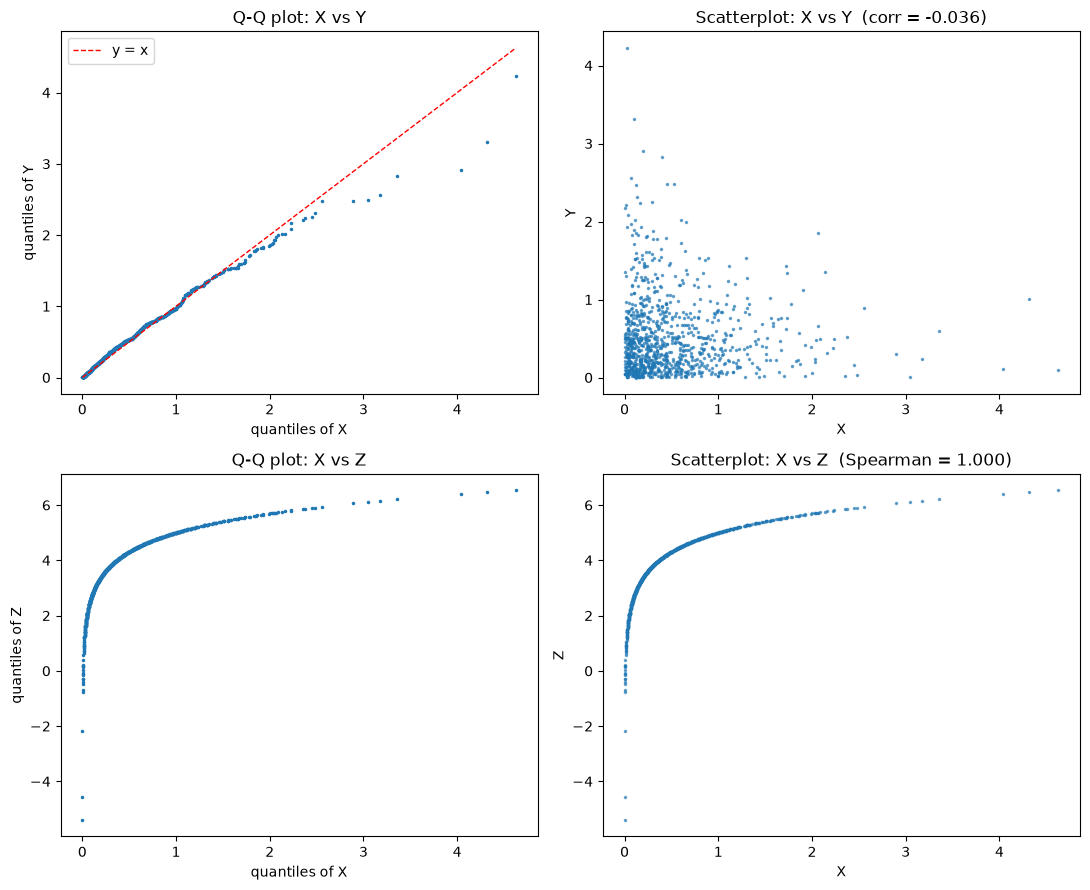

Spearman rank correlation X,Y: 0.0159
Spearman rank correlation X,Z: 1.0000


In [13]:
n_pts = 1000
X = np.random.exponential(scale=1 / 2, size=n_pts)
Y = np.random.exponential(scale=1 / 2, size=n_pts)
Z = np.log(X) + 5

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
lim = max(X.max(), Y.max())
axes[0, 0].plot(np.sort(X), np.sort(Y), ".", ms=3)
axes[0, 0].plot([0, lim], [0, lim], "r--", lw=1, label="y = x")
axes[0, 0].set(title="Q-Q plot: X vs Y", xlabel="quantiles of X", ylabel="quantiles of Y")
axes[0, 0].legend()

axes[0, 1].plot(X, Y, ".", ms=3, alpha=0.6)
axes[0, 1].set(title=f"Scatterplot: X vs Y  (corr = {np.corrcoef(X, Y)[0, 1]:.3f})", xlabel="X", ylabel="Y")

axes[1, 0].plot(np.sort(X), np.sort(Z), ".", ms=3)
axes[1, 0].set(title="Q-Q plot: X vs Z", xlabel="quantiles of X", ylabel="quantiles of Z")

axes[1, 1].plot(X, Z, ".", ms=3, alpha=0.6)
axes[1, 1].set(title=f"Scatterplot: X vs Z  (Spearman = {stats.spearmanr(X, Z)[0]:.3f})", xlabel="X", ylabel="Z")
plt.tight_layout()
plt.show()

print(f"Spearman rank correlation X,Y: {stats.spearmanr(X, Y)[0]:.4f}")
print(f"Spearman rank correlation X,Z: {stats.spearmanr(X, Z)[0]:.4f}")

**(c) Explanation.**

* **X and Y.** The Q-Q plot follows the line $y = x$, so the two samples have the same quantiles. $X$ and $Y$ are
  **identically distributed** (both $\mathcal E(2)$ by construction). In the Q-Q plot the points above about $1.6$ lie below the line $y = x$. Only about $4\%$ of the sample is there, so these extreme quantiles rest on very few observations and are noisy. Elsewhere the Q-Q plot follows $y = x$. The scatterplot is a
  shapeless cloud, densest near the origin, with correlation $\approx 0$. Knowing $X$ tells us nothing about $Y$, as
  expected for **independent** variables.
* **X and Z.** $Z = \ln X + 5$ is a deterministic, strictly increasing function of $X$, so $X$ and $Z$ are completely
  **dependent** (Spearman correlation exactly $1$). They are **not identically distributed**: $Z$ takes negative values
  and has a long left tail, and the Q-Q plot is the curve $z = \ln x + 5$, not a straight line. Because the map is
  increasing, sorting $X$ also sorts $Z$, so the Q-Q plot and the scatterplot show **the same curve**.
* **Takeaway.** The Q-Q plot compares **marginal distributions** only. The scatterplot shows the **joint** behaviour.
  $(X, Y)$ is independent and identically distributed. $(X, Z)$ is dependent and not identically distributed.

### Part 2

**(a)** Each toss is an independent Bernoulli(1/2) trial and $X$ counts the successes in 3 trials, so
$X \sim \text{Bin}(3, 1/2)$: **binomially distributed**. It is discrete with values $0, 1, 2, 3$ and probabilities
$\frac18, \frac38, \frac38, \frac18$, so it is not normal, not Poisson (it is bounded) and not uniform.

**(b)** $E X = np = 1.5$, $\operatorname{Var} X = np(1-p) = 0.75$.

**(c)** $E Y = E X^2 = \operatorname{Var} X + (E X)^2 = 0.75 + 2.25 = 3$. Also
$E Y^2 = E X^4 = \frac{0 + 3 \cdot 1 + 3 \cdot 16 + 81}{8} = 16.5$, so $\operatorname{Var} Y = 16.5 - 9 = 7.5$.

In [14]:
n_rounds = 100
xs = np.random.binomial(3, 0.5, size=n_rounds)
ys = xs**2

vals = np.arange(4)
pmf = stats.binom.pmf(vals, 3, 0.5)
EX, VarX = (vals * pmf).sum(), (vals**2 * pmf).sum() - (vals * pmf).sum()**2
EY, VarY = (vals**2 * pmf).sum(), (vals**4 * pmf).sum() - (vals**2 * pmf).sum()**2

print(f"X: E = {EX:.3f}, Var = {VarX:.3f} | sample mean = {xs.mean():.3f}, sample var = {xs.var(ddof=1):.3f}")
print(f"Y: E = {EY:.3f}, Var = {VarY:.3f} | sample mean = {ys.mean():.3f}, sample var = {ys.var(ddof=1):.3f}")
print(f"friend's claim: (E X)^2 = {EX**2:.3f}  vs  true E[X^2] = {EY:.3f}")
print(f"expected net gain of the friend per round: E[Y] - 3 = {EY - 3:.3f}")

X: E = 1.500, Var = 0.750 | sample mean = 1.560, sample var = 0.714
Y: E = 3.000, Var = 7.500 | sample mean = 3.140, sample var = 7.516
friend's claim: (E X)^2 = 2.250  vs  true E[X^2] = 3.000
expected net gain of the friend per round: E[Y] - 3 = 0.000


**Comment on (b) and (c).** The sample mean and variance of $X$ are close to $1.5$ and $0.75$ (LLN, plus
unbiasedness of $s^2$). The friend's argument is **wrong** for the same reason as in Part 1(a): $g(x) = x^2$ is not
linear, so $E(X^2) \ne (E X)^2$. In fact $E(X^2) = (EX)^2 + \operatorname{Var} X > (EX)^2$, which is Jensen's
inequality for the convex function $x^2$. The extra $0.75$ is exactly the variance. The expected payoff is
$E Y = £3$, which equals the cost, so the expected net gain is $0$ and **the game is fair**. It is still risky:
$\operatorname{Var} Y = 7.5$ (standard deviation $\approx £2.74$, almost equal to the entry fee).

In [15]:
s_y = ys.std(ddof=1)
half = Z95 * s_y / np.sqrt(n_rounds)
print(f"95% CI for E(Y) from {n_rounds} rounds: {ys.mean():.3f} +- {half:.3f}  ->  ({ys.mean() - half:.3f}, {ys.mean() + half:.3f})")
print(f"3.0 in CI: {ys.mean() - half < 3 < ys.mean() + half},   2.9 in CI: {ys.mean() - half < 2.9 < ys.mean() + half}")

sigma_y = np.sqrt(VarY)
delta = 3 - 2.9
n_ci = ceil((Z95 * sigma_y / delta)**2)                       # half-length below 0.1
n_power = ceil(((Z95 + stats.norm.ppf(0.8)) * sigma_y / delta)**2)   # 80% power at 5% level
print(f"\nrounds so that the CI half-length < 0.1: n >= {n_ci}")
print(f"rounds for a 5%-level test with 80% power (3 vs 2.9): n >= {n_power}")

# check the first number by simulation
R = 2000
ys_big = np.random.binomial(3, 0.5, size=(R, n_ci))**2
means = ys_big.mean(axis=1)
halves = Z95 * ys_big.std(axis=1, ddof=1) / np.sqrt(n_ci)
print(f"\nwith n = {n_ci}: share of CIs that exclude 2.9 = {np.mean(means - halves > 2.9):.3f}, "
      f"share that contain 3 = {np.mean(np.abs(means - 3) < halves):.3f}")

95% CI for E(Y) from 100 rounds: 3.140 +- 0.537  ->  (2.603, 3.677)
3.0 in CI: True,   2.9 in CI: True

rounds so that the CI half-length < 0.1: n >= 2882
rounds for a 5%-level test with 80% power (3 vs 2.9): n >= 5887



with n = 2882: share of CIs that exclude 2.9 = 0.505, share that contain 3 = 0.946


**(d)** By the CLT, $\bar Y \approx \mathcal N(E Y, \sigma_Y^2/n)$, so the 95% CI is
$\bar y \pm 1.96\, s/\sqrt{n}$. With $n = 100$ and $s \approx 2.7$ the half-length is about $£0.54$. The interval
contains $3$, but also $2.9$, $3.4$ and everything else within roughly $£0.5$ of $3$. The simulation alone therefore
**cannot** establish fairness: it only shows that the game is not grossly unfair. The exact computation
$E Y = 3$ is what settles the question.

To tell an entry fee of £3 from one of £2.9, the half-length must be below $0.1$:
$n \ge \left(\frac{1.96\sqrt{7.5}}{0.1}\right)^2 \approx 2882$ rounds. Even then, an interval centred near $3$
excludes $2.9$ only about half of the time (see the check above). A test that detects the difference reliably
(5% significance, 80% power) needs $n \ge \left(\frac{(1.96 + 0.84)\sqrt{7.5}}{0.1}\right)^2 \approx 5890$ rounds.

### Conclusions (Task 4)

* $E\,g(X) = g(E X)$ holds only for linear $g$. For convex $g$ (like $1/x$ for $x>0$, or $x^2$), Jensen's inequality gives $E\,g(X) \ge g(EX)$. In 1(b), $E(1/X)$ does not even exist for a normal $X$: $1/\bar X \approx 0.2$ is stable, while $\bar Y$ varied between $-7.1$ and $13.2$ across runs and the LLN does not apply.
* In 1(c), the Q-Q plot compares only marginal distributions and the scatterplot shows dependence. $(X, Y)$ is independent and identically distributed. $(X, Z)$ is perfectly dependent ($Z$ is an increasing function of $X$) and not identically distributed.
* In Part 2, $X \sim \text{Bin}(3, 1/2)$, $E Y = E X^2 = 3$ and $\operatorname{Var} Y = 7.5$. The game **is fair**. The friend confused $E(X^2)$ with $(EX)^2$ and missed exactly $\operatorname{Var} X = 0.75$. The 100 simulated rounds gave $\bar y = 3.14$ with a 95% CI half-length of $0.54$. That is consistent with fairness but equally consistent with fees from about $2.6$ to $3.7$. Telling £3 from £2.9 by simulation needs about $2900$ rounds for a CI of half-length $0.1$, or about $5900$ rounds for a reliable test (80% power). The exact calculation is both cheaper and conclusive.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.